# 04 · Hypothesis-driven comparison and frozen selection
## Summary
Run a bounded pooled-direct model family with chronological validation. Each row describes one origin and one next-day delivery interval; no unobserved intermediate demand is fed recursively. The primary objective is MAE, so point models use absolute-error loss (median objective).
## Context and methods
Compare calendar, demand history, training windows, retraining frequency, one capacity change, past known temperature and RTE correction. Fit every imputer/model on its training slice; use no random validation or test-driven feature choice. Selection uses validation MAE and cold-evening/availability guardrails. Within 0.5% of the best eligible MAE, choose the predefined simpler model. Oracle weather is a separately labeled sensitivity experiment and is ineligible for selection. Deep learning is deferred until simpler comparisons establish a need.

RTE-assisted correction target: `actual demand - RTE forecast available at the origin`. Prediction: `RTE at origin + learned correction`. With these CSVs, availability of the provided RTE column remains an explicit retrospective assumption.

In [1]:
%matplotlib inline
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "config/forecast_contract.json").exists())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.common import load_contract, prepare_directories, plotting_style, write_json, fingerprint
contract = load_contract(ROOT)
prepare_directories(ROOT)
plotting_style()
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_rows", 16)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

In [2]:
from dataclasses import asdict
from src.storage import read_features,read_labels,read_predictions
from src.backtest import experiments,model_replay,select_candidate,feature_columns,fit_at_origin,stress_inputs
from src.metrics import scorecard,matched_scorecard,segment_scorecard
features=read_features(ROOT/"data/origin_snapshots/history_features.csv.gz")
labels=read_labels(ROOT/"data/processed/evaluation_labels.csv.gz")
registry=experiments()
register=pd.DataFrame([asdict(e) for e in registry])
register.to_csv(ROOT/"reports/experiment_register.csv",index=False)
display(register[["name","hypothesis","window_days","retrain_days","status"]])

,name,hypothesis,window_days,retrain_days,status
0,calendar,Calendar alone explains recurring demand profi...,365.000,28,retrospective
1,history_365,Available demand history improves calendar-onl...,365.000,28,retrospective
2,history_730,A two-year window improves seasonal coverage.,730.000,28,retrospective
3,history_expanding,Longer history outweighs structural drift.,NaN,28,retrospective
4,history_weekly_fit,More frequent retraining tracks changes.,365.000,7,retrospective
5,history_more_leaves,Modestly higher capacity captures interactions.,365.000,28,retrospective
6,history_past_weather,Temperature already observed at cutoff adds in...,365.000,28,retrospective
7,rte_correction_proxy,Calendar/history predict residual RTE errors b...,365.000,28,retrospective
8,weather_archive,Authentic archived weather improves demand for...,365.000,28,gated_no_verified_archive
9,oracle_weather_sensitivity,"Recorded future weather measures sensitivity, ...",365.000,28,oracle_sensitivity_only


### 1. Replay non-oracle candidates on chronological validation

In [3]:
start=contract["validation_folds"][0]["start"]; end=contract["validation_folds"][-1]["end"]
predictions=[read_predictions(ROOT/"reports/forecasts/baselines_validation.csv.gz")]
for experiment in registry:
    if experiment.oracle or experiment.status.startswith("gated"): continue
    print("Validation:",experiment.name,flush=True)
    predictions.append(model_replay(features,labels,start,end,experiment,ROOT,contract))
validation=pd.concat(predictions,ignore_index=True)
validation.to_csv(ROOT/"reports/forecasts/all_validation.csv.gz",index=False,compression="gzip")

Validation: calendar


Validation: history_365


Validation: history_730


Validation: history_expanding


Validation: history_weekly_fit


Validation: history_more_leaves


Validation: history_past_weather


Validation: rte_correction_proxy


### 2. Score common observations, guardrails and separate validation folds

,model,eligible_targets,scored,missing_targets,availability,MAE_MW,RMSE_MW,bias_actual_minus_forecast_MW,WAPE_percent
11,rte_correction_proxy,"17,542.000","17,542.000",2.000,1.000,878.426,"1,158.336",33.607,1.754
3,rte_bias_proxy,"17,542.000","17,542.000",2.000,1.000,"1,013.216","1,312.219",-0.738,2.023
2,rte_proxy,"17,542.000","17,542.000",2.000,1.000,"1,388.401","1,720.107","1,085.367",2.773
7,history_expanding,"17,542.000","17,542.000",2.000,1.000,"1,944.432","2,723.269",11.732,3.883
6,history_730,"17,542.000","17,542.000",2.000,1.000,"2,089.780","2,954.551",253.395,4.173
10,history_past_weather,"17,542.000","17,542.000",2.000,1.000,"2,193.511","3,066.609",335.602,4.380
8,history_weekly_fit,"17,542.000","17,542.000",2.000,1.000,"2,272.455","3,198.591",207.947,4.538
9,history_more_leaves,"17,542.000","17,542.000",2.000,1.000,"2,319.023","3,294.858",220.761,4.631
5,history_365,"17,542.000","17,542.000",2.000,1.000,"2,324.962","3,300.570",297.021,4.643
4,calendar,"17,542.000","17,542.000",2.000,1.000,"3,074.566","4,370.773",514.400,6.140


,model,eligible_targets,scored,missing_targets,availability,MAE_MW,RMSE_MW,bias_actual_minus_forecast_MW,WAPE_percent,cold_MAE_ratio_to_RTE,passes_guardrails
11,rte_correction_proxy,"17,542.000","17,542.000",2.000,1.000,878.426,"1,158.336",33.607,1.754,0.712,True
7,history_expanding,"17,542.000","17,542.000",2.000,1.000,"1,944.432","2,723.269",11.732,3.883,2.213,False
6,history_730,"17,542.000","17,542.000",2.000,1.000,"2,089.780","2,954.551",253.395,4.173,2.783,False
10,history_past_weather,"17,542.000","17,542.000",2.000,1.000,"2,193.511","3,066.609",335.602,4.380,2.714,False
8,history_weekly_fit,"17,542.000","17,542.000",2.000,1.000,"2,272.455","3,198.591",207.947,4.538,2.868,False
9,history_more_leaves,"17,542.000","17,542.000",2.000,1.000,"2,319.023","3,294.858",220.761,4.631,2.837,False
5,history_365,"17,542.000","17,542.000",2.000,1.000,"2,324.962","3,300.570",297.021,4.643,3.032,False
4,calendar,"17,542.000","17,542.000",2.000,1.000,"3,074.566","4,370.773",514.400,6.140,4.116,False


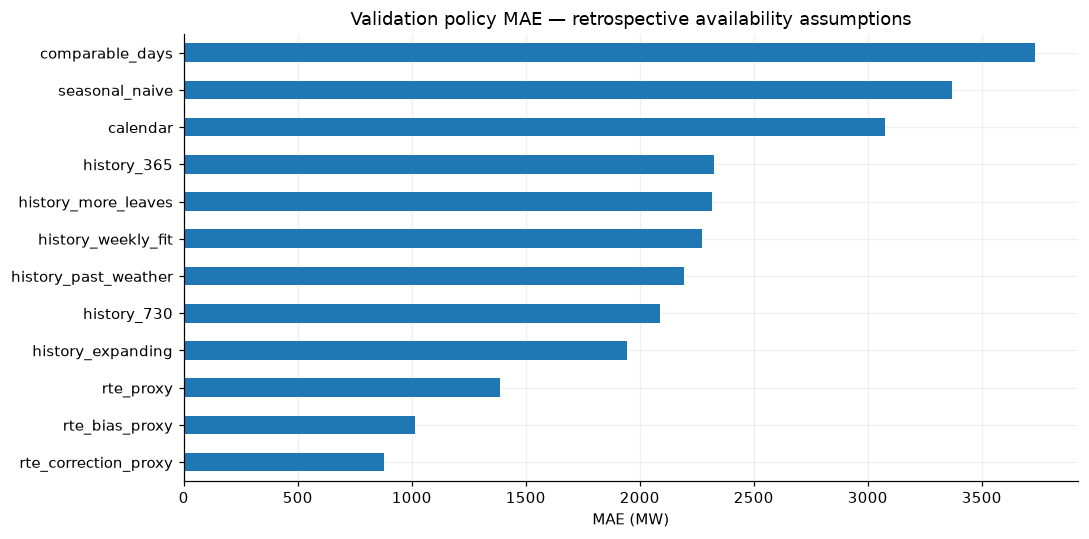

Frozen candidate: rte_correction_proxy


In [4]:
scores=scorecard(validation,labels)
segments=segment_scorecard(validation,labels,contract)
common_scores,_=matched_scorecard(validation,labels,"raw_prediction_mw")
winner,selection=select_candidate(scores,segments,registry,contract)
scores.to_csv(ROOT/"reports/scorecards/model_validation_policy.csv",index=False)
segments.to_csv(ROOT/"reports/scorecards/model_validation_segments.csv",index=False)
common_scores.to_csv(ROOT/"reports/scorecards/model_validation_common_raw.csv",index=False)
selection.to_csv(ROOT/"reports/scorecards/selection_guardrails.csv",index=False)
display(scores.sort_values("MAE_MW")); display(selection.sort_values("MAE_MW"))
fold_scores=[]
for fold in contract["validation_folds"]:
    subset=validation.loc[validation.local_day.ge(fold["start"]) & validation.local_day.lt(fold["end"])]
    table=scorecard(subset,labels); table["fold"]=fold["name"]; fold_scores.append(table)
pd.concat(fold_scores).to_csv(ROOT/"reports/scorecards/validation_by_fold.csv",index=False)
if winner is None: raise RuntimeError("No candidate passes frozen guardrails. Keep the baselines; investigate using validation only.")
selected=next(e for e in registry if e.name==winner)
frozen={"experiment":asdict(selected),"contract_sha256":fingerprint(ROOT/"config/forecast_contract.json"),"selection_rule":"validation MAE, guardrails, 0.5% simplicity tolerance", "oracle_ineligible":True,"test_previously_explored":True}
write_json(ROOT/"config/frozen_candidate.json",frozen)
fig,ax=plt.subplots(figsize=(10,5))
scores.set_index("model").MAE_MW.sort_values().plot.barh(ax=ax)
ax.set(title="Validation policy MAE — retrospective availability assumptions",xlabel="MAE (MW)",ylabel="")
plt.tight_layout(); plt.show()
print("Frozen candidate:",winner)

### 3. Input stress tests with the same fallback policy

In [5]:
from src.features import prediction_fallback
stress_origin=features.loc[features.local_day.ge("2025-06-01"),"origin"].min()
stress_day=features.loc[features.origin.eq(stress_origin)]
stress_model,_=fit_at_origin(features,labels,stress_origin,selected,contract)
stress_rows=[]
for scenario in ("missing_demand_lags","missing_rte","stale_weather","rapid_demand_change"):
    changed=stress_inputs(stress_day,scenario)
    raw=stress_model.predict(changed[feature_columns(selected)])
    if selected.correction: raw+=changed.rte_at_origin_mw.to_numpy()
    if scenario=="missing_demand_lags" and "history" in selected.groups: raw[:]=np.nan
    p,source=prediction_fallback(changed,raw,selected.correction)
    stress_rows.append({"scenario":scenario,"delivered_intervals":int(p.notna().sum()),"fallback_intervals":int(source.ne("model").sum()),"minimum_MW":p.min(),"maximum_MW":p.max()})
stress_table=pd.DataFrame(stress_rows)
stress_table.to_csv(ROOT/"reports/scorecards/input_stress_tests.csv",index=False)
display(stress_table)

,scenario,delivered_intervals,fallback_intervals,minimum_MW,maximum_MW
0,missing_demand_lags,24,24,"31,150.000","43,262.000"
1,missing_rte,24,24,"31,670.000","43,227.000"
2,stale_weather,24,0,"32,149.445","44,837.694"
3,rapid_demand_change,24,0,"32,341.243","44,727.534"


### 4. Future recorded weather: sensitivity only, excluded from selection

In [6]:
from src.data import read_audited
data=read_audited(ROOT)
oracle=features.copy()
oracle["oracle_temperature_c"]=data.temperature_c.reindex(pd.DatetimeIndex(oracle.delivery_time)).to_numpy()
oracle["oracle_heating_c"]=(18-oracle.oracle_temperature_c).clip(lower=0)
oracle["oracle_cooling_c"]=(oracle.oracle_temperature_c-22).clip(lower=0)
oracle_experiment=next(e for e in registry if e.oracle)
oracle_predictions=model_replay(oracle,labels,start,end,oracle_experiment,ROOT,contract,phase="oracle_validation")
oracle_scores=scorecard(oracle_predictions,labels)
oracle_scores["interpretation"]="recorded future weather; not deployable evidence"
oracle_scores.to_csv(ROOT/"reports/scorecards/oracle_weather_sensitivity.csv",index=False)
display(oracle_scores)

,model,eligible_targets,scored,missing_targets,availability,MAE_MW,RMSE_MW,bias_actual_minus_forecast_MW,WAPE_percent,interpretation
0,oracle_weather_sensitivity,"17,542.000","17,542.000",2.000,1.000,"1,808.449","2,517.781",273.075,3.611,recorded future weather; not deployable evidence


## Takeaways
The candidate and its preprocessing, window, retraining and fallback policies are frozen in `config/frozen_candidate.json`. Future test-period labels may enter later scheduled fits only after their assumed publication time; this online rule was fixed before test scoring. Changing the policy after reading test results would require a new experiment. Authentic weather and RTE-vintage experiments remain gated.